# 05 — Validación del pronóstico sin el motivo de consulta

## Qué pregunta responde y por qué importa

Se sostiene que el motivo escrito en la nota de triage no hace falta para pronosticar el volumen de urgencias. Las notas las escriben enfermeras y están sujetas a interpretación; bastaría con el conteo y la fecha, enfrentados a factores externos como clima, salud pública, eventos y desastres. Este cuaderno mide si los datos respaldan esa idea: qué parte del conteo diario y semanal queda por explicar una vez descontado el calendario, qué variables externas se asocian con lo que sobra y si alguna mejora el pronóstico fuera de muestra a una semana.

El motivo de consulta nunca podía ser entrada de un pronóstico, porque se conoce cuando el paciente ya llegó. Lo que se pone a prueba es otra cosa: si el conteo, el calendario y los factores externos bastan, y si la edad puede sustituir al motivo para estudiar el mecanismo respiratorio con más historia (6,7 años) y sin interpretación de nadie. Este cuaderno es el **control** de lo que vino después: mide qué se logra con el calendario antes de añadir información externa.

## Diseño, fijado antes de mirar los resultados

- **Ventana de análisis:** del 2022-03-01 al 2026-09-20. Quedan fuera la COVID y la ola de ómicron, y el último día de la serie, que está incompleto.
- **Semana:** de lunes a domingo, etiquetada con el domingo en que termina.
- **Control de calendario:** día de la semana, festivo, puente, víspera y día posterior a un festivo, quincena, vacaciones escolares, Semana Santa, temporada de Navidad y de fin de año, regreso a clases, efecto fijo de año y un escalón el 2025-11-01. No incluye el mes del año, porque la estacionalidad forma parte de lo que se quiere explicar.
- **Anomalías de clima:** contra la climatología del mismo mes (2020-2026), en desviaciones típicas.
- **Ruptura de seca a lluvia (semanal):** z de lluvia de la semana ≥ +0,5 y media de z de las tres semanas previas ≤ −0,5.
- **Enfriamiento brusco (semanal):** z de temperatura de la semana menos la media de z de las tres previas ≤ −1.
- **Indicador pediátrico:** residuo, en logaritmo, de los 0-14 años en la semana anterior.

Las dos variables de transición se definieron antes de correr el análisis, pero no se preregistraron formalmente: todo lo de este cuaderno es exploratorio.

## Datos

Solo archivos agregados del repositorio; ningún texto clínico, ningún identificador, ninguna conexión a la base. El origen de cada fuente externa está en el cuaderno 03.

| Dato | Archivo | Fuente |
|---|---|---|
| Triage diario del SES | `salidas/triage_diario.parquet` | base del hospital, agregada por día |
| Triage por banda de edad (0-4, 5-14, 15-44, 45-64, 65+) | `salidas/triage_edad.parquet` | la misma base, agregada |
| Triage por nivel; se usan los niveles con «G», que el análisis trata como obstétricos | `salidas/triage_nivel.parquet` | la misma base, agregada |
| Festivos, puentes, vacaciones | `calendarios/calendario_Colombia.csv` | festivos de ley y reglas propias |
| Clima diario | `calendarios/clima_unificado.csv.gz` | IDEAM, METAR La Nubia, Open-Meteo, NASA POWER |
| Ventanas de vigilancia, ENSO, volcán | `calendarios/vigilancia_salud_manizales_caldas.csv` | calendario manual |
| Eventos y desastres | `calendarios/eventos_manizales_2020_2026.csv`, `desastres_manizales_2020_2026.csv` | calendarios manuales |

Dos precisiones sobre las fuentes. La lluvia sale del clima unificado, donde los días con el pluviómetro de La Nubia en cero sostenido mientras llovía se tratan como ausentes y no como sequía. Y los calendarios de vigilancia, eventos y desastres son los manuales que existían al empezar el análisis; las series reales del SIVIGILA y del Ministerio de Defensa se integraron después, y este cuaderno ayuda a explicar por qué hizo falta.

In [1]:
import sys, pathlib, warnings, subprocess, re
from math import erf, sqrt
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
    "ytick.color": TINTA2, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "font.size": 10, "legend.frameon": False})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

INI, FIN = "2022-03-01", "2026-09-20"          # fuera de COVID y omicron; el ultimo dia de la serie esta incompleto
COVID = ("2020-03-15", "2022-02-28")
dias = pd.date_range("2020-01-01", FIN)
pct = lambda z: (np.exp(z) - 1) * 100

d = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet")
tot = d.set_index(pd.to_datetime(d["dia"]))["triages"].astype(float).reindex(dias)   # dia sin filas = NULO
e = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet"); e["dia"] = pd.to_datetime(e["dia"])
ed = e.pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0)  # en un subgrupo, 0 es 0
ped = ed[[c for c in ed.columns if c.startswith("0-") or c.startswith("5-")]].sum(axis=1)
b04 = ed[[c for c in ed.columns if c.startswith("0-")]].sum(axis=1)
nv = pd.read_parquet(RAIZ / "salidas/triage_nivel.parquet"); nv["dia"] = pd.to_datetime(nv["dia"])
obst = nv[nv["nivel"].astype(str).str.contains("G")].groupby("dia")["n"].sum().reindex(dias).fillna(0)
D = pd.DataFrame({"total": tot, "ped": ped, "b04": b04, "obst": obst})

CAL = ["es_festivo", "es_puente", "es_vispera_festivo", "es_post_festivo", "es_quincena",
       "es_vacaciones_escolares", "es_semana_santa", "es_temporada_navidad",
       "es_temporada_fin_anio", "es_regreso_colegio"]
k = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
k = k[CAL + ["dia_semana"]].apply(pd.to_numeric, errors="coerce").fillna(0)
c = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
c = c[["precip_consenso_mm", "temp_media_consenso", "humedad_consenso", "temp_min_consenso", "precip_con_estacion"]]
D = D.join(k).join(c)
print(f"{len(D)} días, {D.index.min():%Y-%m-%d} a {D.index.max():%Y-%m-%d}; bandas de edad: {list(ed.columns)}")

2455 días, 2020-01-01 a 2026-09-20; bandas de edad: ['0-4', '15-44', '45-64', '5-14', '65-+', 'sin edad']


---
# 0. Tres días caídos del registro quedan como nulos

Un día sin filas en el total es una caída del registro, no cero pacientes: un servicio de urgencias no cierra. Se trata como nulo. Un día con menos del 40 % de lo esperado por el calendario y el año, fuera de la COVID, es una caída parcial y se excluye. En un subgrupo (una banda de edad) un día sin filas sí puede ser cero, pero en un día caído el subgrupo también queda nulo.

días sin ninguna fila: ['2024-03-19', '2024-03-20']
días con < 40 % de lo esperado: {'2024-03-21': '40 triages, esperados 232'}


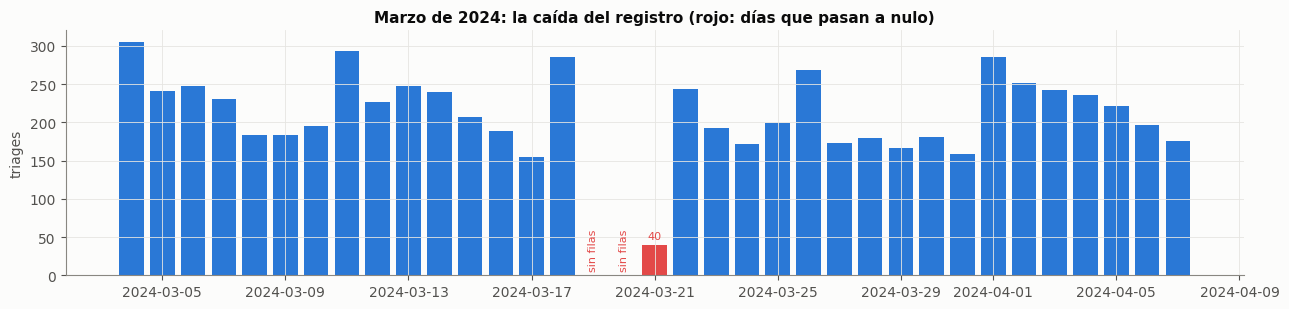

In [2]:
# Caidas del registro (regla del proyecto): un dia SIN filas es nulo, no cero; un dia con menos del
# 40 % de lo esperado por el calendario y el anio, fuera de COVID, es una caida parcial y se excluye.
Z0 = pd.concat([pd.get_dummies(D["dia_semana"].astype(int), prefix="d", drop_first=True).astype(float), D[CAL],
                pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)], axis=1)
Z0.insert(0, "c", 1.0)
fuera_covid = ~dias.to_series().between(*COVID).values
ok0 = fuera_covid & D.total.notna().values
b0, *_ = np.linalg.lstsq(Z0.values[ok0], np.log(D.total.values[ok0]), rcond=None)
res0 = np.log(D.total) - Z0.values @ b0
sin_filas = D.total.isna()
parcial = (res0 < np.log(.4)) & fuera_covid
print("días sin ninguna fila:", [f"{x:%Y-%m-%d}" for x in D.index[sin_filas]])
print("días con < 40 % de lo esperado:", {f"{x:%Y-%m-%d}": f"{int(D.total[x])} triages, esperados {np.exp(np.log(D.total[x]) - res0[x]):.0f}"
                                          for x in D.index[parcial]})
caido = sin_filas | parcial
D.loc[caido, ["total", "ped", "b04", "obst"]] = np.nan
D["adult"] = D["total"] - D["ped"]
D["adult_noobst"] = D["adult"] - D["obst"]

v = D.loc["2024-03-04":"2024-04-07", "total"]
orig = tot.loc[v.index]
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.bar(orig.index, orig.fillna(0), color=[ROJO if caido[x] else AZUL for x in orig.index], width=.8)
for x in orig.index[caido.loc[orig.index]]:
    ax.text(x, (orig.fillna(0)[x]) + 5, "sin filas" if sin_filas[x] else f"{int(orig[x])}", ha="center", va="bottom", fontsize=8, color=ROJO, rotation=90 if sin_filas[x] else 0)
ax.set_ylabel("triages"); ax.set_title("Marzo de 2024: la caída del registro (rojo: días que pasan a nulo)")
plt.tight_layout(); plt.show()

El 19 y el 20 de marzo de 2024 no tienen ninguna fila, y el 21 tiene 40 triages contra 232 esperados por el calendario y el año. Los tres días quedan nulos, como muestra la figura en rojo. La semana que los contiene (la que termina el 2024-03-24) queda con el desenlace nulo y no se elimina: así los rezagos y las medias móviles no saltan por encima del hueco, algo que ocurriría al borrar la fila y haría que un «pronóstico a una semana» apuntara en realidad a dos.

El tratamiento importa para el ruido diario: la celda de la sección 2.1 mide cuánto sube la desviación típica si el 21 de marzo se deja como día normal.

---
# 1. Los calendarios manuales repiten el mes del año

Antes de medir un efecto conviene mirar la variable. Esta sección examina si las ventanas de vigilancia dicen algo que el mes del año no diga ya, y lo mide con el R² de cada bandera diaria explicada solo por 12 indicadores de mes.

vigilancia: 321 filas; ventana_estacional (misma fecha cada año): 216 (67%)
  por ámbito: {'nacional': 192, 'caldas': 89, 'manizales': 40}
  con número de casos: 28 | de Manizales con casos: 6
eventos: 99 filas; categorías: {'religioso': 26, 'civico': 22, 'musical': 10, 'feria': 7, 'taurino': 7, 'teatro': 7, 'literario': 7, 'deportivo': 7, 'emergencia': 3, 'academico': 2, 'universitario': 1}
desastres: 17 filas; calidad: {'confirmado': 9, 'pendiente_verificacion': 4, 'fecha_aproximada': 2, 'confirmado_cifras_en_actualizacion': 2}


días por año con El Niño / La Niña: {'nino': {2022: 0, 2023: 214, 2024: 152, 2025: 0, 2026: 112}, 'nina': {2022: 153, 2023: 59, 2024: 31, 2025: 120, 2026: 0}}
  ira_ventana: R2 explicado solo por el mes del año = 0.926
  vsr_ventana: R2 explicado solo por el mes del año = 1.000
  flu_ventana: R2 explicado solo por el mes del año = 1.000
  dengue_ventana: R2 explicado solo por el mes del año = 0.750


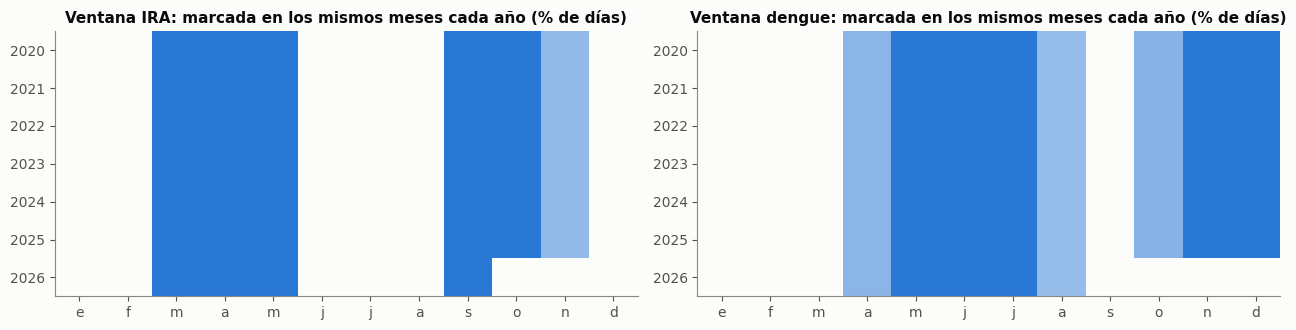

In [3]:
def banderas(df, filtro, ini="fecha_inicio", fin="fecha_fin"):
    s = pd.Series(0.0, index=D.index)
    for _, r in df[filtro].iterrows():
        a = pd.to_datetime(r[ini], errors="coerce"); b = pd.to_datetime(r[fin], errors="coerce")
        if pd.isna(a): continue
        if pd.isna(b): b = a
        s.loc[a:b] = 1
    return s

v = pd.read_csv(RAIZ / "calendarios/vigilancia_salud_manizales_caldas.csv")
ev = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
de = pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv")
print(f"vigilancia: {len(v)} filas; ventana_estacional (misma fecha cada año): "
      f"{(v.estado == 'ventana_estacional').sum()} ({(v.estado == 'ventana_estacional').mean():.0%})")
print("  por ámbito:", v.ambito_territorial.value_counts().to_dict())
print("  con número de casos:", v.casos.notna().sum(), "| de Manizales con casos:",
      ((v.ambito_territorial == "manizales") & v.casos.notna()).sum())
print(f"eventos: {len(ev)} filas; categorías:", ev.categoria.value_counts().to_dict())
print(f"desastres: {len(de)} filas; calidad:", de.calidad_dato.value_counts().to_dict())

X = pd.DataFrame(index=D.index)
X["ira_ventana"] = banderas(v, (v.subcategoria == "temporada_IRA") & (v.estado == "ventana_estacional"))
X["vsr_ventana"] = banderas(v, (v.subcategoria == "vsr"))
X["flu_ventana"] = banderas(v, (v.subcategoria == "influenza") & (v.estado == "ventana_estacional"))
X["dengue_ventana"] = banderas(v, (v.subcategoria == "dengue") & (v.estado == "ventana_estacional"))
X["nino"] = banderas(v, v.subcategoria == "el_nino")
X["nina"] = banderas(v, v.subcategoria == "la_nina")
X["volcan_naranja"] = banderas(v, v.nombre_evento.str.contains("Naranja", case=False, na=False) |
                               v.descripcion.str.contains("alerta naranja", case=False, na=False) &
                               (v.subcategoria == "actividad_volcanica"))
X["ceniza"] = banderas(v, v.subcategoria == "ceniza_volcanica")
evm = ev[(ev.municipio == "Manizales") & ev.estado.isin(["realizado", "hibrido"])]
X["evento"] = banderas(evm, slice(None))
X["feria"] = banderas(evm, evm.nombre_evento.str.contains("Feria de Manizales"))
X["desastre"] = banderas(de, de.ambito.isin(["municipal", "institucional"]) & (de.calidad_dato != "pendiente_verificacion") &
                         (pd.to_datetime(de.fecha_fin) - pd.to_datetime(de.fecha_inicio)).dt.days.le(7))
X["terremoto"] = 0.0; X.loc["2026-08-10":"2026-08-23", "terremoto"] = 1
D = D.join(X)
print("días por año con El Niño / La Niña:", D.loc[INI:FIN, ["nino", "nina"]].groupby(D.loc[INI:FIN].index.year).sum().astype(int).to_dict())

m = pd.get_dummies(D.index.month).astype(float).values
for col in ["ira_ventana", "vsr_ventana", "flu_ventana", "dengue_ventana"]:
    y = D[col].values
    beta, *_ = np.linalg.lstsq(m, y, rcond=None)
    print(f"  {col}: R2 explicado solo por el mes del año = {1 - ((y - m @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
cmap = LinearSegmentedColormap.from_list("s", [SUP, AZUL])
for ax, col, t in zip(axes, ["ira_ventana", "dengue_ventana"], ["Ventana IRA", "Ventana dengue"]):
    H = D[col].groupby([D.index.year, D.index.month]).mean().unstack()
    ax.imshow(H.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(12), ["e", "f", "m", "a", "m", "j", "j", "a", "s", "o", "n", "d"]); ax.set_yticks(range(len(H)), H.index)
    ax.grid(False); ax.set_title(f"{t}: marcada en los mismos meses cada año (% de días)")
plt.tight_layout(); plt.show()

**Los calendarios manuales son, en su mayoría, calendario disfrazado.** De las 321 filas de vigilancia, 216 (67 %) son «ventana estacional», con las mismas fechas cada año. El mes del año explica el 92,6 % de la bandera de infección respiratoria aguda (IRA), el 100 % de las de VSR e influenza y el 75 % de la de dengue. La figura lo muestra: las franjas oscuras caen en los mismos meses todos los años. Solo 28 filas traen número de casos, y de Manizales apenas 6. Los eventos son 99 filas, casi todas recurrentes anuales (religiosos, cívicos, musicales), y los desastres, 17, cuatro de ellas pendientes de verificar.

Usar estas banderas como predictores equivale a proyectar el calendario, no a predecir. Esto no dice que la vigilancia sea inútil, sino que estas variables, tal como estaban, no traen información propia; por eso se sustituyeron por series reales (cuaderno 03). El conteo de días con El Niño y La Niña por año, impreso arriba, anticipa otro límite: ambos fenómenos ocupan años completos y se confunden con el efecto fijo de año.

---
# 2. Tras el calendario queda un 13 % de la varianza diaria por explicar

Para cada serie diaria (total, adultos y 0-14 años) se ajusta el logaritmo del conteo contra el control, y luego contra el control más la estacionalidad anual (tres armónicos). El **piso de Poisson**, aproximadamente 1/μ en escala logarítmica, es el ruido que ninguna variable puede explicar: el azar de contar personas. Lo que queda por encima de ese piso es lo que podría explicar una variable externa.

In [4]:
W = D.loc[INI:FIN].copy()
W = W[W.total.notna()]
def diseno_control(df, con_mes=False, con_tendencia=True):
    Z = pd.get_dummies(df["dia_semana"].astype(int), prefix="dow", drop_first=True).astype(float)
    Z = pd.concat([Z, df[CAL]], axis=1)
    if con_tendencia:
        Z = pd.concat([Z, pd.get_dummies(df.index.year, prefix="a", drop_first=True).set_index(df.index).astype(float)], axis=1)
        Z["escalon_2025_11"] = (df.index >= "2025-11-01").astype(float)
    if con_mes:
        doy = df.index.dayofyear.values
        for h in (1, 2, 3):
            Z[f"s{h}"] = np.sin(2*np.pi*h*doy/365.25); Z[f"c{h}"] = np.cos(2*np.pi*h*doy/365.25)
    Z.insert(0, "const", 1.0)
    return Z

def ols(y, Z):
    b, *_ = np.linalg.lstsq(Z.values, y, rcond=None)
    return b, y - Z.values @ b

filas = []
for nombre in ["total", "adult", "ped"]:
    y = np.log(W[nombre].clip(lower=0.5)).values
    _, r0 = ols(y, diseno_control(W)); _, r1 = ols(y, diseno_control(W, con_mes=True))
    piso = np.mean(1 / W[nombre].clip(lower=1))
    filas.append({"serie": nombre, "media por día": W[nombre].mean(), "sd residuo, control": r0.std(),
                  "sd, + estacionalidad": r1.std(), "piso de Poisson": np.sqrt(piso),
                  "explicable que queda": np.sqrt(max(r1.var() - piso, 0)),
                  "% de la varianza residual": 100 * max(r1.var() - piso, 0) / r1.var(), "AR1 del residuo": pd.Series(r1).autocorr()})
T1 = pd.DataFrame(filas).set_index("serie").round(3)
print(f"{len(W)} días en la ventana {INI} a {FIN}")
T1

1662 días en la ventana 2022-03-01 a 2026-09-20


,media por día,"sd residuo, control","sd, + estacionalidad",piso de Poisson,explicable que queda,% de la varianza residual,AR1 del residuo
serie,,,,,,,
total,198.122,0.115,0.109,0.073,0.082,55.607,0.307
adult,181.900,0.116,0.112,0.076,0.082,53.855,0.304
ped,16.223,0.390,0.363,0.273,0.240,43.454,0.340


El residuo diario del total, tras el control, tiene una desviación típica de 0,115 (alrededor de 11,5 %), que baja a 0,109 al añadir la estacionalidad. El piso de Poisson es 0,073, de modo que **el 56 % de la varianza residual podría explicarse** y el resto es azar de conteo. La autocorrelación del residuo a un día es +0,31: lo que sobra no es ruido blanco, hay algo que dura varios días.

En los niños, con 16,2 por día, el piso de Poisson es 0,273 y el residuo del control 0,390: la mayor parte del ruido diario pediátrico es azar de contar números pequeños. Por eso la escala semanal resulta más informativa en esa serie (sección 3).

La siguiente celda descompone de dónde viene la variación del total diario, bloque por bloque.

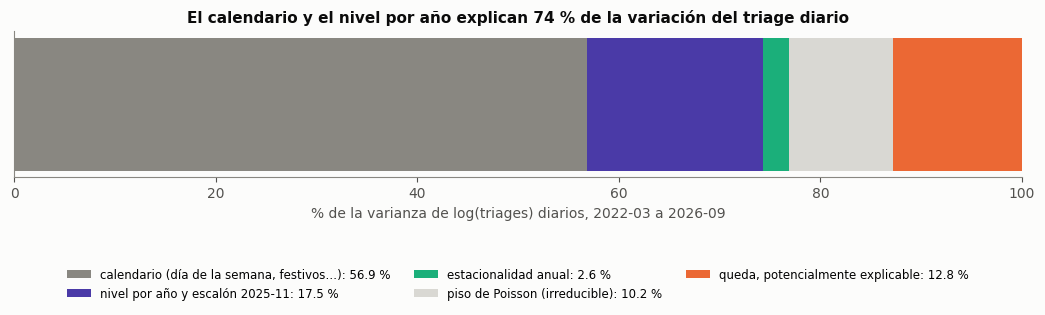

media diaria por año: {2020: 105.7, 2021: 149.3, 2022: 189.6, 2023: 192.4, 2024: 226.9, 2025: 199.6, 2026: 172.6}


,%
"calendario (día de la semana, festivos…)",56.9
nivel por año y escalón 2025-11,17.5
estacionalidad anual,2.6
piso de Poisson (irreducible),10.2
"queda, potencialmente explicable",12.8


In [5]:
y = np.log(W["total"]).values
def r2(Z): b, *_ = np.linalg.lstsq(Z.values, y, rcond=None); return 1 - (y - Z.values @ b).var() / y.var()
r_cal = r2(diseno_control(W, con_tendencia=False)); r_ct = r2(diseno_control(W)); r_cts = r2(diseno_control(W, con_mes=True))
poisson = np.mean(1 / W["total"]) / np.log(W["total"]).var()
E = pd.Series({"calendario (día de la semana, festivos…)": r_cal, "nivel por año y escalón 2025-11": r_ct - r_cal,
               "estacionalidad anual": r_cts - r_ct, "piso de Poisson (irreducible)": poisson,
               "queda, potencialmente explicable": 1 - r_cts - poisson}) * 100
fig, ax = plt.subplots(figsize=(13, 1.9))
izq = 0
for (nom, val), col in zip(E.items(), [MUDO, VIOLETA, AQUA, "#d9d8d3", NARANJA]):
    ax.barh(0, val, left=izq, color=col, label=f"{nom}: {val:.1f} %"); izq += val
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False); ax.set_xlabel("% de la varianza de log(triages) diarios, 2022-03 a 2026-09")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.55), ncol=3, fontsize=8.5)
ax.set_title(f"El calendario y el nivel por año explican {E.iloc[0] + E.iloc[1]:.0f} % de la variación del triage diario")
plt.show()
print("media diaria por año:", {int(a): round(x, 1) for a, x in D["total"].groupby(D.index.year).mean().items()})
E.round(1).to_frame("%")

| Bloque | % de la varianza de log(triages) diarios |
|---|---|
| Calendario (día de la semana, festivos…) | **56,9** |
| Nivel por año y escalón 2025-11 | +17,5 |
| Estacionalidad anual | +2,6 |
| Piso de Poisson (irreducible) | 10,2 |
| Queda, potencialmente explicable | 12,8 |

La forma del año pesa muy poco frente al día de la semana y al nivel de cada año: la estacionalidad se lleva el 2,6 % y el nivel por año con su escalón, el 17,5 %, casi siete veces más. Lo que mueve el volumen de un año a otro pesa mucho más que la estación. El margen real para una variable externa es del orden del 13 % de la varianza diaria. Las medias diarias por año (2022: 189,6; 2023: 192,4; 2024: 226,9; 2025: 199,6; 2026: 172,6) muestran que el nivel sube hasta 2024 y cae después.

## 2.1 El control diario sobre los 615 días de referencia

El control de calendario de este cuaderno usa una ventana de 1.662 días y residuos dentro de muestra. Una medición previa del control de calendario, con otra especificación, se hizo sobre 615 días (del 2025-01-08 al 2026-09-14), con origen rodante y 215 días fuera de muestra: dio un MAPE de 10,13 %, un residuo diario de 12,6 %, una autocorrelación de +0,423 y un 77,2 % de acierto en «mañana supera la media de los últimos 7 días» (base 50,7 %). La celda siguiente repite el control con el diseño de este cuaderno (calendario más el escalón 2025-11) sobre esa misma ventana, para dejar claro qué cifras coinciden y cuáles no.

In [6]:
# Control diario, origen rodante, sobre los 615 días del 2025-01-08 al 2026-09-14 (215 fuera de muestra)
V = D.loc["2025-01-08":"2026-09-14"].copy()
assert V["total"].notna().all()
yv = np.log(V["total"].values)
Zv = pd.concat([pd.get_dummies(V["dia_semana"].astype(int), prefix="d", drop_first=True).astype(float), V[CAL]], axis=1)
Zv = Zv.loc[:, Zv.std() > 0]
Zv["escalon_2025_11"] = (V.index >= "2025-11-01").astype(float)
Zv.insert(0, "const", 1.0); Xv = Zv.values
N_V, N0 = len(yv), len(yv) - 215
bv, *_ = np.linalg.lstsq(Xv, yv, rcond=None); rv = yv - Xv @ bv
pron = np.array([Xv[t] @ np.linalg.lstsq(Xv[:t], yv[:t], rcond=None)[0] for t in range(N0, N_V)])
real_v, mod_v = np.exp(yv[N0:]), np.exp(pron)
sem_pasada = np.exp(yv[N0 - 7:N_V - 7]); mm7 = np.array([np.exp(yv[t - 7:t]).mean() for t in range(N0, N_V)])
mape_v = lambda f: 100 * np.mean(np.abs(real_v - f) / real_v)
sube_real = real_v > mm7
res_v = pd.Series({"días en la ventana": N_V, "días fuera de muestra": N_V - N0,
    "R² del control, dentro de muestra %": 100 * (1 - rv.var() / yv.var()),
    "sd del residuo diario %": 100 * rv.std(), "autocorrelación del residuo a 1 día": pd.Series(rv).autocorr(),
    "MAPE calendario + escalón, origen rodante %": mape_v(mod_v),
    "MAPE mismo día de la semana pasada %": mape_v(sem_pasada), "MAPE media móvil de 7 días %": mape_v(mm7),
    "acierto «mañana > media de 7 días» %": 100 * np.mean((mod_v > mm7) == sube_real),
    "base de esa pregunta %": 100 * max(sube_real.mean(), 1 - sube_real.mean())})
res_v.round(3).to_frame("valor")

,valor
días en la ventana,615.000
días fuera de muestra,215.000
"R² del control, dentro de muestra %",70.333
sd del residuo diario %,12.300
autocorrelación del residuo a 1 día,0.438
"MAPE calendario + escalón, origen rodante %",11.407
MAPE mismo día de la semana pasada %,13.370
MAPE media móvil de 7 días %,14.740
acierto «mañana > media de 7 días» %,70.233
base de esa pregunta %,51.163


| Cifra | Medición previa | Este cuaderno, 615 días |
|---|---|---|
| MAPE del control, origen rodante, 215 días | 10,13 % | 11,41 % |
| MAPE «mismo día de la semana pasada» | 13,82 % | 13,37 % |
| MAPE media móvil de 7 días | 14,98 % | 14,74 % |
| Desviación típica del residuo diario | 12,6 % | 12,3 % |
| Autocorrelación del residuo a 1 día | +0,423 | +0,438 |
| Acierto de «mañana > media de 7 días» | 77,2 % (base 50,7 %) | 70,2 % (base 51,2 %) |

**Las cifras son del mismo orden pero no coinciden.** Las dos bases simples y el ruido diario salen casi iguales; el MAPE del control y el acierto de «sube» salen peores aquí, 11,4 % contra 10,1 % y 70 % contra 77 %. La diferencia se atribuye a la especificación del control (en esta celda solo entran calendario y escalón), pero no se logró reproducir la cifra original, y las de esta celda son las que este cuaderno sostiene. Dos hechos sí coinciden: el residuo diario del control está entre 11 % y 13 %, y su autocorrelación a un día, entre +0,3 y +0,44, indica que lo que sobra es persistente.

Estas cifras diarias tampoco son comparables con el MAPE semanal de la sección 7 (alrededor del 5 %): un total semanal suma siete días y el error relativo baja de 11 % a 5 %.

In [7]:
# Sensibilidad: el ruido diario si el 21 de marzo de 2024 (40 triages de 232 esperados) se deja como día normal
sel_p = parcial.reindex(D.loc[INI:FIN].index).fillna(False).values
W_sens = D.loc[INI:FIN].copy()
W_sens.loc[sel_p, "total"] = tot.reindex(W_sens.index)[sel_p]
W_sens = W_sens[W_sens.total.notna()]
_, r_sens = ols(np.log(W_sens["total"].clip(lower=0.5)).values, diseno_control(W_sens))
_, r_base = ols(np.log(W["total"].clip(lower=0.5)).values, diseno_control(W))
print(f"sd del residuo diario del total, con el día caído excluido: {r_base.std():.3f}; con el 21-mar-2024 incluido: {r_sens.std():.3f} ({len(W_sens)} días contra {len(W)})")

sd del residuo diario del total, con el día caído excluido: 0.115; con el 21-mar-2024 incluido: 0.123 (1663 días contra 1662)


Dejar el 21 de marzo de 2024 como si fuera un día normal sube la desviación típica del residuo diario de 0,115 a 0,123: un solo día mal tratado mueve el ruido casi un 7 %, razón suficiente para excluirlo.

---
# 3. A escala semanal casi todo el residuo es explicable, y es muy persistente

Se repite el cálculo sumando por semana (de lunes a domingo). Solo entran las semanas con sus siete días válidos. Sumar siete días baja el piso de Poisson, y si existe una señal lenta debería asomar aquí.

In [8]:
agg = {"total": "sum", "adult": "sum", "ped": "sum", "b04": "sum", "adult_noobst": "sum",
       "precip_consenso_mm": "sum", "temp_media_consenso": "mean", "humedad_consenso": "mean", "temp_min_consenso": "mean"}
agg.update({col: "mean" for col in CAL}); agg.update({col: "max" for col in X.columns})
agg["evento"] = "sum"; agg["feria"] = "sum"
S = D.loc["2020-01-06":FIN].resample("W-SUN").agg(agg)
S["n_dias"] = D.loc["2020-01-06":FIN, "total"].resample("W-SUN").count()
DESEN = ["total", "adult", "ped", "b04", "adult_noobst"]
S.loc[S.n_dias < 7, DESEN] = np.nan
print("semanas incompletas (quedan como fila con desenlace nulo):", [f"{x:%Y-%m-%d}" for x in S.index[S.n_dias < 7]])
mes = S.index.month
for col, nom in [("precip_consenso_mm", "zp"), ("temp_media_consenso", "zt"), ("humedad_consenso", "zh"), ("temp_min_consenso", "ztmin")]:
    g = S[col].groupby(mes)
    S[nom] = (S[col] - g.transform("mean")) / g.transform("std")
S["zp_prev3"] = S["zp"].shift(1).rolling(3).mean()
S["zt_prev3"] = S["zt"].shift(1).rolling(3).mean()
S["ruptura"] = ((S.zp >= 0.5) & (S.zp_prev3 <= -0.5)).astype(float).where(S.zp.notna() & S.zp_prev3.notna())
S["enfriamiento"] = ((S.zt - S.zt_prev3) <= -1).astype(float).where(S.zt.notna() & S.zt_prev3.notna())

SW = S.loc[INI:FIN].copy()
OK = SW.total.notna()
def diseno_sem(df, con_mes=False):
    Z = df[CAL].copy()
    Z = pd.concat([Z, pd.get_dummies(df.index.year, prefix="a", drop_first=True).set_index(df.index).astype(float)], axis=1)
    Z["escalon_2025_11"] = (df.index >= "2025-11-01").astype(float)
    if con_mes:
        w = df.index.isocalendar().week.values.astype(float)
        for h in (1, 2, 3):
            Z[f"s{h}"] = np.sin(2*np.pi*h*w/52.18); Z[f"c{h}"] = np.cos(2*np.pi*h*w/52.18)
    Z.insert(0, "const", 1.0)
    return Z

filas = []
for nombre in ["total", "adult", "ped", "b04"]:
    y = np.log(SW.loc[OK, nombre].clip(lower=0.5)).values
    _, r0 = ols(y, diseno_sem(SW[OK])); _, r1 = ols(y, diseno_sem(SW[OK], True))
    piso = np.mean(1 / SW.loc[OK, nombre].clip(lower=1))
    SW[f"r0_{nombre}"] = pd.Series(r0, index=SW.index[OK]); SW[f"r1_{nombre}"] = pd.Series(r1, index=SW.index[OK])
    filas.append({"serie": nombre, "media por semana": SW.loc[OK, nombre].mean(), "sd residuo, control": r0.std(),
                  "sd, + estacionalidad": r1.std(), "piso de Poisson": np.sqrt(piso),
                  "% explicable": 100 * max(r1.var() - piso, 0) / r1.var(), "AR1": SW[f"r1_{nombre}"].autocorr(),
                  "% que se come la estacionalidad": 100 * (1 - r1.var() / r0.var())})
T2 = pd.DataFrame(filas).set_index("serie").round(3)
print(f"{int(OK.sum())} semanas completas de {len(SW)} en la ventana")
T2

semanas incompletas (quedan como fila con desenlace nulo): ['2024-03-24']


237 semanas completas de 238 en la ventana


,media por semana,"sd residuo, control","sd, + estacionalidad",piso de Poisson,% explicable,AR1,% que se come la estacionalidad
serie,,,,,,,
total,1386.468,0.073,0.064,0.027,82.074,0.517,23.702
adult,1272.781,0.072,0.065,0.028,81.359,0.532,16.306
ped,113.688,0.253,0.216,0.098,79.345,0.655,27.060
b04,46.582,0.309,0.263,0.157,64.501,0.516,27.367


| Total, semanal (237 semanas) | |
|---|---|
| Desviación típica del residuo tras el control | 0,073 |
| … y tras la estacionalidad | **0,064** (≈ 6,4 %) |
| Piso de Poisson | 0,027 |
| Parte que podría explicarse | **82 %** |
| Autocorrelación a una semana | **+0,52** |

**A escala semanal el residuo del total es en su mayor parte explicable y muy persistente.** La estacionalidad se lleva el 23,7 % del residuo semanal del total y el 27,1 % del de los niños. En la serie de 0-14 años la autocorrelación es +0,66: lo pediátrico se mueve en bloques de semanas, como una temporada. La persistencia del total (+0,52) fija la vara de cualquier pronóstico: tiene que ganarle primero a «la semana que viene será como esta». La única semana incompleta (la que termina el 2024-03-24) queda fuera de los cálculos y se conserva como fila nula.

---
# 4. En los niños el clima deja huella; en el total, casi ninguna

Cada variable se prueba por separado sobre el control más la estacionalidad, con errores estándar HAC (4 rezagos), porque el residuo está autocorrelacionado. Las de clima se prueban a 0, 1 y 2 semanas de rezago. El efecto es el cambio porcentual del conteo por una desviación típica de la variable, o por estar presente en el caso de las banderas. El asterisco marca un intervalo que no cruza el cero. Son 27 filas de variable y rezago por tres series, 81 pruebas: por azar saldrían varias marcas, y no hay corrección por comparaciones múltiples.

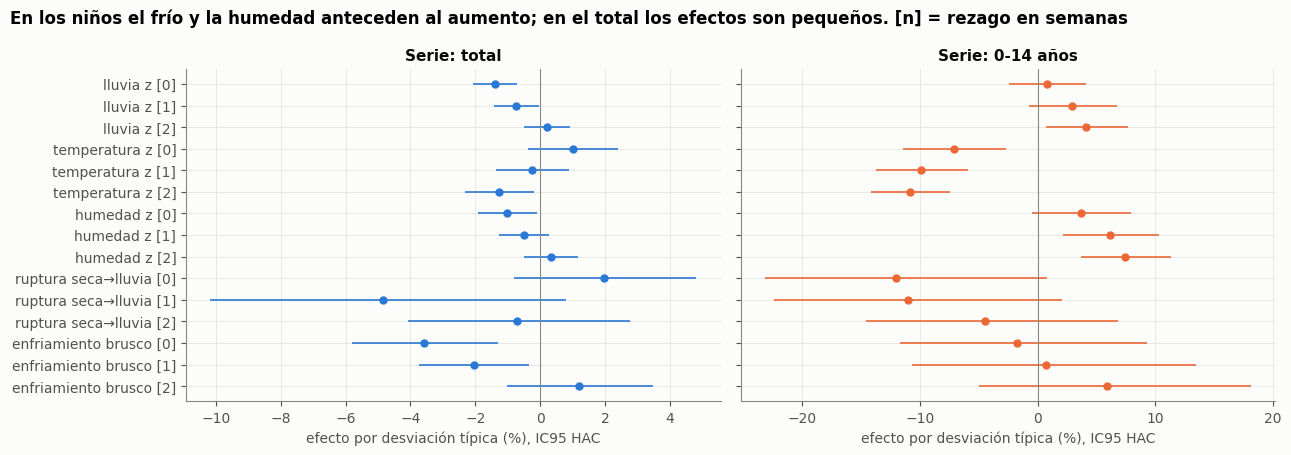

serie                                            total                adultos              0-14 años
variable                 rezago                                                                     
lluvia z                 0          -1.4 [-2.1; -0.7]*     -1.5 [-2.2; -0.8]*      +0.8 [-2.5; +4.1]
                         1          -0.7 [-1.4; -0.1]*     -1.0 [-1.7; -0.3]*      +3.0 [-0.7; +6.8]
                         2           +0.2 [-0.5; +0.9]      -0.1 [-0.8; +0.6]     +4.1 [+0.7; +7.7]*
temperatura z            0           +1.0 [-0.4; +2.4]     +1.6 [+0.2; +3.0]*    -7.1 [-11.4; -2.7]*
                         1           -0.3 [-1.4; +0.9]      +0.5 [-0.7; +1.6]    -9.9 [-13.7; -5.9]*
                         2          -1.3 [-2.3; -0.2]*      -0.5 [-1.7; +0.6]   -10.9 [-14.1; -7.5]*
humedad z                0          -1.0 [-1.9; -0.1]*     -1.3 [-2.3; -0.4]*      +3.7 [-0.5; +7.9]
                         1           -0.5 [-1.3; +0.3]     -1.0 [-1.8; -0.2]*    +6.2 [+2.2; +10.4]*
                         2           +0.3 [-0.5; +1.2]      -0.2 [-1.1; +0.6]    +7.4 [+3.7; +11.3]*
temp. mínima z           0           -0.5 [-1.8; +0.7]      -0.2 [-1.5; +1.1]     -5.2 [-9.3; -0.9]*
                         1           -1.0 [-2.5; +0.5]      -0.7 [-2.2; +0.9]     -5.7 [-9.9; -1.4]*
                         2          -1.3 [-2.3; -0.2]*      -0.9 [-2.0; +0.2]    -6.1 [-10.0; -2.0]*
ruptura seca→lluvia      0           +2.0 [-0.8; +4.8]     +3.0 [+0.3; +5.9]*    -12.0 [-23.2; +0.8]
                         1          -4.8 [-10.2; +0.8]      -4.3 [-9.5; +1.2]    -11.0 [-22.5; +2.1]
                         2           -0.7 [-4.1; +2.8]      -0.3 [-3.6; +3.1]     -4.5 [-14.6; +6.8]
enfriamiento brusco      0          -3.6 [-5.8; -1.3]*     -3.7 [-5.7; -1.6]*     -1.7 [-11.7; +9.3]
                         1          -2.0 [-3.7; -0.3]*     -2.2 [-4.0; -0.4]*    +0.7 [-10.7; +13.5]
                         2           +1.2 [-1.0; +3.5]      +0.8 [-1.5; +3.1]     +5.9 [-5.0; +18.1]
El Niño                  0           -0.8 [-3.9; +2.5]      +1.4 [-1.9; +4.9]  -27.2 [-34.6; -18.9]*
La Niña                  0           +1.8 [-1.4; +5.1]      +0.6 [-2.7; +4.1]   +21.8 [+6.2; +39.7]*
volcán en naranja        0                 (constante)            (constante)            (constante)
caída de ceniza          0           -0.1 [-5.5; +5.6]      +0.2 [-6.2; +7.1]    -7.2 [-24.5; +14.1]
días de evento (por día) 0           +0.0 [-0.4; +0.4]      +0.0 [-0.4; +0.5]      -0.4 [-2.0; +1.3]
días de Feria (por día)  0           +0.2 [-0.8; +1.1]      +0.3 [-0.7; +1.3]      -2.0 [-4.8; +0.9]
terremoto 2026-08        0       -21.5 [-26.9; -15.7]*  -20.7 [-26.2; -14.9]*  -29.5 [-40.1; -17.2]*
ventana IRA del INS      0         +7.1 [+2.7; +11.7]*    +6.5 [+2.0; +11.2]*    +12.2 [-4.0; +31.1]
ventana dengue           0         -6.6 [-10.2; -3.0]*     -6.2 [-9.8; -2.4]*    -10.9 [-22.2; +2.1]

In [9]:
def hac_se(y, Z, lags=4):
    Zv = Z.values
    b, *_ = np.linalg.lstsq(Zv, y, rcond=None); u = y - Zv @ b
    XtX_inv = np.linalg.pinv(Zv.T @ Zv)
    S0 = (Zv * u[:, None]).T @ (Zv * u[:, None])
    for L in range(1, lags + 1):
        w = 1 - L / (lags + 1)
        G = (Zv[L:] * u[L:, None]).T @ (Zv[:-L] * u[:-L, None])
        S0 += w * (G + G.T)
    return b, np.sqrt(np.diag(XtX_inv @ S0 @ XtX_inv))

cands = [("zp", "lluvia z"), ("zt", "temperatura z"), ("zh", "humedad z"), ("ztmin", "temp. mínima z"),
         ("ruptura", "ruptura seca→lluvia"), ("enfriamiento", "enfriamiento brusco"),
         ("nino", "El Niño"), ("nina", "La Niña"), ("volcan_naranja", "volcán en naranja"),
         ("ceniza", "caída de ceniza"), ("evento", "días de evento (por día)"),
         ("feria", "días de Feria (por día)"), ("terremoto", "terremoto 2026-08"),
         ("ira_ventana", "ventana IRA del INS"), ("dengue_ventana", "ventana dengue")]
filas = []
for col, et in cands:
    for lag in ((0, 1, 2) if col in ("zp", "zt", "zh", "ztmin", "ruptura", "enfriamiento") else (0,)):
        for yname, yet in [("total", "total"), ("adult", "adultos"), ("ped", "0-14 años")]:
            xv = SW[col].shift(lag)
            ok = xv.notna() & OK
            Z = diseno_sem(SW, True)[ok].copy(); Z["x"] = xv[ok].values
            if Z["x"].std() == 0:
                filas.append({"variable": et, "rezago": lag, "serie": yet, "celda": "(constante)"}); continue
            b, se = hac_se(np.log(SW.loc[ok, yname].clip(lower=0.5)).values, Z)
            bx, sx = b[-1], se[-1]
            filas.append({"variable": et, "rezago": lag, "serie": yet, "efecto %": pct(bx), "bajo": pct(bx - 1.96 * sx),
                          "alto": pct(bx + 1.96 * sx), "t": bx / sx,
                          "celda": f"{pct(bx):+.1f} [{pct(bx-1.96*sx):+.1f}; {pct(bx+1.96*sx):+.1f}]" + ("*" if abs(bx / sx) > 1.96 else "")})
T3 = pd.DataFrame(filas)

sel = T3[T3.variable.isin(["lluvia z", "temperatura z", "humedad z", "enfriamiento brusco", "ruptura seca→lluvia"]) & T3.serie.isin(["total", "0-14 años"])]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (s_, col) in zip(axes, [("total", AZUL), ("0-14 años", NARANJA)]):
    h = sel[sel.serie == s_].reset_index(drop=True)
    ax.errorbar(h["efecto %"], range(len(h)), xerr=[h["efecto %"] - h["bajo"], h["alto"] - h["efecto %"]], fmt="o", color=col, ms=5, lw=1.2)
    ax.axvline(0, color=MUDO, lw=.8); ax.set_title(f"Serie: {s_}"); ax.set_xlabel("efecto por desviación típica (%), IC95 HAC")
    ax.set_yticks(range(len(h)), [f"{a} [{b}]" for a, b in zip(h.variable, h.rezago)])
axes[0].invert_yaxis()
fig.suptitle("En los niños el frío y la humedad anteceden al aumento; en el total los efectos son pequeños. [n] = rezago en semanas",
             fontweight="bold", x=.01, ha="left")
plt.tight_layout(); plt.show()
T3.pivot_table(index=["variable", "rezago"], columns="serie", values="celda", aggfunc="first", sort=False)[["total", "adultos", "0-14 años"]]

La figura compara el efecto de las variables de clima en el total y en los 0-14 años. En los niños los intervalos se separan del cero con la dirección del mecanismo respiratorio; en el total quedan pegados al cero.

| | total | 0-14 años |
|---|---|---|
| Temperatura, rezago 1 / 2 semanas | −0,3 / −1,3 % | **−9,9 / −10,9 %** (frío, más niños) |
| Humedad, rezago 1 / 2 | −0,5 / +0,3 % | **+6,2 / +7,4 %** |
| Lluvia, misma semana | **−1,4 %** [−2,1; −0,7] (llueve, menos consultas) | +0,8 % |
| Lluvia, rezago 2 | +0,2 % | +4,1 % [+0,7; +7,7] |
| Enfriamiento brusco, misma semana | **−3,6 %** [−5,8; −1,3] | −1,7 % |
| Ruptura de seca a lluvia, misma semana | +2,0 % [−0,8; +4,8] | −12,0 % [−23,2; +0,8] |
| La Niña / El Niño | +1,8 / −0,8 % | **+21,8 / −27,2 %** |
| Terremoto de agosto de 2026 (2 semanas) | **−21,5 %** [−26,9; −15,7] | −29,5 % |
| Días de evento / de Feria (por día) | +0,0 / +0,2 % | −0,4 / −2,0 % |

**El mecanismo respiratorio se ve sin el motivo, en la edad:** el frío y la humedad preceden en una y dos semanas a más consultas de niños, con efectos de 6 a 11 % por desviación típica. El resto de la lectura matiza:

- **En el total, el enfriamiento brusco acompaña a menos consultas la misma semana**, no a más; es lo contrario de la hipótesis, a rezago cero. Una sola semana de lluvia muy fuerte con menos triage (sección 8) encaja con el −1,4 % de la lluvia, pero es un caso aislado.
- **La ruptura de seca a lluvia no se distingue de cero en el total**, con intervalos de unos ±3 a ±5 puntos. En los adultos la misma semana sale marcada con +3,0 % [+0,3; +5,9], una marca entre 81 pruebas. En los niños el signo es contrario a la hipótesis (−12,0 %), aunque el intervalo cruza el cero. El cuaderno 07 mide otra cosa (0-4 años, días 7-20 después de cada episodio), y ahí el signo es positivo.
- **ENSO está confundido con el año.** En la ventana, El Niño cae en 2023 (214 días), 2024 (152) y 2026 (112), y La Niña sobre todo en 2022 (153) y 2025 (120). Como el modelo lleva un efecto fijo por año, el ±25 % en los niños no se puede separar del nivel de cada año.
- **Las ventanas de IRA (+7,1 %) y de dengue (−6,6 %) salen significativas en el total.** Son las mismas fechas cada año, o sea una estacionalidad más fina que tres armónicos, no información nueva (sección 1).
- **Eventos y Feria, medidos como días de la semana, dan cero.** Medidos por tipo de pago y con otro reloj, la Feria sí deja huella (ver las conclusiones).

Los resultados con lluvia dependen del clima unificado actual: con el pluviómetro de La Nubia en cero sostenido tratado como ausente, la lluvia a una semana en el total queda en −0,7 % [−1,4; −0,1] y la ruptura de seca a lluvia llega a 10 semanas.

## 4.1 El residuo pediátrico no anticipa a los adultos

Si el mecanismo fuera «los niños se enferman primero y contagian en casa», el residuo de 0-14 años de la semana anterior debería anunciar a los adultos de esta semana. Se prueba incluyendo el propio rezago del desenlace, para no confundir persistencia con anticipación.

In [10]:
SW["r1_ped_l1"] = SW["r1_ped"].shift(1)
filas = []
for yname in ["adult", "adult_noobst", "total"]:
    Z = diseno_sem(SW, True); Z["ped_l1"] = SW["r1_ped_l1"]; Z["y_l1"] = SW[f"r1_{'adult' if yname != 'total' else 'total'}"].shift(1)
    ok = Z.notna().all(axis=1) & SW[yname].notna()
    b, se = hac_se(np.log(SW.loc[ok, yname].clip(lower=0.5)).values, Z[ok])
    filas.append({"serie": yname, "efecto de +10 % en 0-14 (t-1), %": round((np.exp(b[-2] * np.log(1.1)) - 1) * 100, 2),
                  "t": round(b[-2] / se[-2], 2), "t del propio rezago": round(b[-1] / se[-1], 2), "semanas": int(ok.sum())})
print(f"correlación de residuos (control + estacionalidad): 0-14 contra adultos r = {SW['r1_ped'].corr(SW['r1_adult']):+.2f}; "
      f"0-4 contra adultos r = {SW['r1_b04'].corr(SW['r1_adult']):+.2f}")
print(f"residuos sin estacionalidad (solo control): 0-14 contra adultos r = {SW['r0_ped'].corr(SW['r0_adult']):+.2f}")
pd.DataFrame(filas).set_index("serie")

correlación de residuos (control + estacionalidad): 0-14 contra adultos r = +0.08; 0-4 contra adultos r = +0.05
residuos sin estacionalidad (solo control): 0-14 contra adultos r = +0.24


,"efecto de +10 % en 0-14 (t-1), %",t,t del propio rezago,semanas
serie,,,,
adult,-0.22,-1.80,11.55,235
adult_noobst,-0.06,-0.45,12.21,235
total,-0.12,-0.93,10.85,235


**Lo pediátrico no anticipa a los adultos.** Un 10 % más de niños la semana anterior va con −0,22 % de adultos (t = −1,80), y el efecto desaparece al quitar lo obstétrico (−0,06 %, t = −0,45). La correlación del residuo pediátrico con el de adultos en la misma semana es +0,08. Sin quitar la estacionalidad llega a +0,24, lo que indica que comparten la estación y no la semana. **En el total, lo pediátrico se diluye:** lo que se ve en los niños no llega al conteo total.

---
# 5. Las variables externas juntas no superan al azar en el total, y sí en los niños

Se ajustan a la vez las 11 variables externas con sus rezagos (19 columnas) sobre el residuo semanal. Para saber cuánto R² da el azar con tantas columnas, se baraja la serie en bloques de 8 semanas, para conservar la autocorrelación, 300 veces, y se compara con el percentil 95.

In [11]:
ext = ["zp", "zt", "zh", "ztmin", "ruptura", "enfriamiento", "nino", "nina", "ceniza", "evento", "feria"]
Ex = SW[ext].copy()
for c_ in ["zp", "zt", "zh", "ztmin"]:
    Ex[c_ + "_l1"] = SW[c_].shift(1); Ex[c_ + "_l2"] = SW[c_].shift(2)
filas = []
for yname, et in [("total", "total"), ("adult", "adultos"), ("ped", "0-14 años")]:
    yv = SW[f"r1_{yname}"]
    ok = Ex.notna().all(axis=1) & yv.notna()
    Z = np.column_stack([np.ones(ok.sum()), Ex[ok].values])
    b, *_ = np.linalg.lstsq(Z, yv[ok].values, rcond=None)
    r2_ = 1 - (yv[ok].values - Z @ b).var() / yv[ok].var()
    p_ = Z.shape[1] - 1; r2a = 1 - (1 - r2_) * (ok.sum() - 1) / (ok.sum() - p_ - 1)
    rng = np.random.default_rng(0); nul = []; yy = yv[ok].values
    for _ in range(300):                       # azar: la serie barajada en bloques de 8 semanas
        bl = [yy[i:i+8] for i in range(0, len(yy), 8)]; rng.shuffle(bl); ys = np.concatenate(bl)
        bb, *_ = np.linalg.lstsq(Z, ys, rcond=None); nul.append(1 - (ys - Z @ bb).var() / ys.var())
    filas.append({"serie": et, "R2": round(r2_, 3), "R2 ajustado": round(r2a, 3), "p95 del azar": round(np.quantile(nul, .95), 3),
                  "semanas": int(ok.sum()), "variables": p_})
T4 = pd.DataFrame(filas).set_index("serie")
T4

,R2,R2 ajustado,p95 del azar,semanas,variables
serie,,,,,
total,0.117,0.038,0.169,232,19
adultos,0.117,0.038,0.169,232,19
0-14 años,0.260,0.193,0.204,232,19


| Serie | R² | p95 del azar | Lectura |
|---|---|---|---|
| Total | 0,117 | 0,169 | indistinguible del azar |
| Adultos | 0,117 | 0,169 | indistinguible |
| **0-14 años** | **0,260** | 0,204 | por encima del azar |

**Las externas no explican el total más allá del azar y sí explican parte del pediátrico.** Es la dilución que cabía esperar: el efecto existe en un subgrupo y se pierde en el total. El margen del pediátrico sobre el azar es modesto (0,056 de R²), y el R² ajustado del total, 0,038, indica que casi todo su ajuste procede de columnas añadidas.

---
# 6. La potencia no alcanza para contrastar la transición sobre el total

Se calcula cuántas semanas tiene cada bandera y qué efecto mínimo se detectaría con 80 % de potencia y α = 0,05, sin corregir y corrigiendo por la autocorrelación, que reduce el número efectivo de semanas.

In [12]:
n = int(SW.loc[OK, "r1_total"].notna().sum()); sd = SW["r1_total"].std()
filas = []
for frac in (0.05, 0.10, 0.25):
    se = sd / np.sqrt(n * frac * (1 - frac))
    filas.append({"bandera presente en": f"{frac:.0%} de las semanas", "efecto mínimo detectable %": round(pct(2.8 * se), 1)})
ar1 = SW["r1_total"].autocorr()
neff = n * (1 - ar1) / (1 + ar1)
mde_ar = pct(2.8 * sd / np.sqrt(neff * .1 * .9))
print(f"sd del residuo semanal {sd:.3f}, {n} semanas; con AR1 {ar1:+.2f} el n efectivo es ~{neff:.0f} semanas "
      f"y el mínimo detectable de una bandera del 10 % sube a {mde_ar:.1f} %")
pd.DataFrame(filas).set_index("bandera presente en")

sd del residuo semanal 0.064, 237 semanas; con AR1 +0.52 el n efectivo es ~76 semanas y el mínimo detectable de una bandera del 10 % sube a 7.1 %


,efecto mínimo detectable %
bandera presente en,
5% de las semanas,5.5
10% de las semanas,4.0
25% de las semanas,2.7


Hay 10 semanas de ruptura de seca a lluvia en 237 (4,2 %) y 20 de enfriamiento brusco en 234 (8,5 %). Una bandera presente en el 5 % de las semanas necesita un efecto de 5,5 % para detectarse, sin corregir. Con la autocorrelación de +0,52, el número efectivo baja a unas 76 semanas, y una bandera del 10 % necesita entonces un efecto de 7,1 %. La literatura publica efectos de clima sobre urgencias del 2 al 10 %.

**La hipótesis de transición sobre el total no se puede contrastar con este diseño, con o sin motivo.** No es que sea falsa: el instrumento es más grueso que el efecto. Los intervalos de la sección 4 para la ruptura (de ±3 a ±5,5 % en el total) lo confirman: aun siendo nulos, no excluyen un efecto dentro del rango publicado.

---
# 7. Ninguna variable externa mejora el pronóstico semanal del total

La pregunta es si, con lo que se sabe al cierre de la semana t, se puede pronosticar cuántos triages habrá en t+1 y si van a subir. El origen es rodante, del 2024-01 al 2026-08, y cada semana se reentrena solo con el pasado. El objetivo es log(t+1) menos el nivel, definido como la media de las 4 últimas semanas; el modelo es una regresión ridge con λ = 3, y la probabilidad de «sube» sale de la normal con la dispersión de los residuos del entrenamiento.

| Modelo | Qué sabe |
|---|---|
| Ingenuo | la semana t+1 será igual que la t |
| M0 | nivel + calendario de la semana que viene (se conoce de antemano) + escalón |
| M1 | M0 + estacionalidad + la última semana contra su nivel: **proyección** |
| M2 | M1 + externas conocidas en t: clima de t y t−1, transiciones, cuota pediátrica, evento o Feria de t+1, ENSO |
| M2b | M2 sin estacionalidad |
| M3 | **oráculo**: M2 + el clima observado de t+1, que en operación no se tendría |

Todos los modelos se evalúan sobre las mismas semanas. La cuota pediátrica de M2 usa la media de 8 semanas con un mínimo de 6, para no perder semanas por el hueco de marzo de 2024.

132 semanas de origen, 2024-01-07 a 2026-08-16; suben el 47.0% (Brier de una moneda = 0,250)


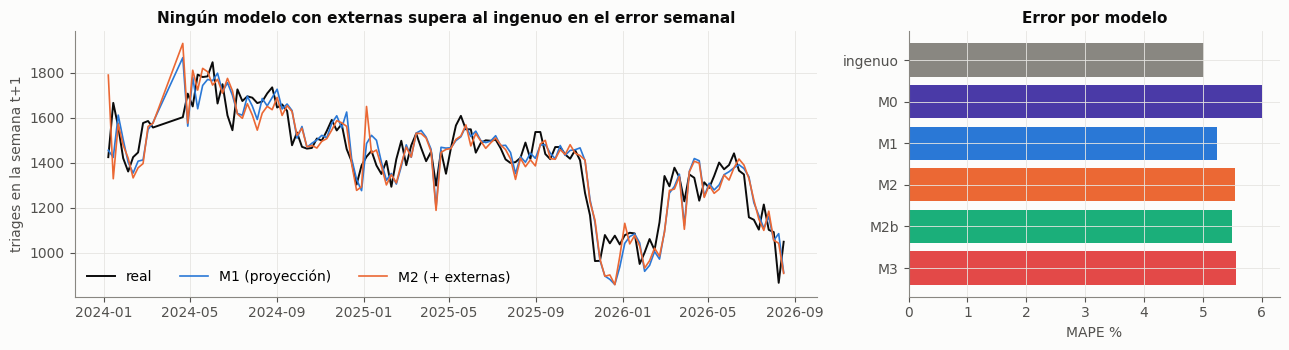

,MAPE %,acierto de «sube» %,Brier
modelo,,,
ingenuo (= semana actual),5.020,NaN,NaN
M0 nivel + calendario,6.010,61.364,0.245
M1 + estacionalidad (proyección),5.233,57.576,0.242
M2 + externas conocidas en t,5.538,58.333,0.254
"M2b solo externas, sin estacionalidad",5.502,59.091,0.245
M3 oráculo: + clima observado de t+1,5.569,56.061,0.257


In [13]:
Phi = lambda z: 0.5 * (1 + np.vectorize(erf)(z / sqrt(2)))
def ridge(Xtr, ytr, lam=3.0):
    mu, sd_ = Xtr.mean(0), Xtr.std(0); sd_[sd_ == 0] = 1
    Xs = (Xtr - mu) / sd_
    b = np.linalg.solve(Xs.T @ Xs + lam * np.eye(Xs.shape[1]), Xs.T @ (ytr - ytr.mean()))
    return lambda Xn: ytr.mean() + ((Xn - mu) / sd_) @ b

F = S.loc["2021-09-01":FIN].copy()
F["ly"] = np.log(F["total"])
F["nivel4"] = F["ly"].rolling(4).mean()          # conocido al cierre de la semana t; nulo si la ventana toca el hueco
F["objetivo"] = F["ly"].shift(-1) - F["nivel4"]
F["sube"] = (F["total"].shift(-1) > F["total"]).astype(float).where(F["total"].shift(-1).notna() & F["total"].notna())
for col in CAL:
    F[f"dcal_{col}"] = F[col].shift(-1) - F[col].rolling(4).mean()
w = F.index.isocalendar().week.values.astype(float) + 1
for h in (1, 2, 3):
    F[f"s{h}"] = np.sin(2*np.pi*h*w/52.18); F[f"c{h}"] = np.cos(2*np.pi*h*w/52.18)
F["escalon"] = (F.index >= "2025-11-01").astype(float)
F["mom"] = F["ly"] - F["nivel4"]
F["pedsh"] = np.log(F["ped"] / F["total"])
F["pedsh_d"] = F["pedsh"] - F["pedsh"].rolling(8, min_periods=6).mean().shift(1)
F["zp_l"] = F["zp"]; F["zp_l1"] = F["zp"].shift(1); F["zt_l"] = F["zt"]; F["zh_l"] = F["zh"]
F["rupt_l"] = F["ruptura"]; F["enfr_l"] = F["enfriamiento"]
F["evento_sig"] = F["evento"].shift(-1); F["feria_sig"] = F["feria"].shift(-1)
F["nino_l"] = F["nino"]; F["nina_l"] = F["nina"]
F["zp_sig"] = F["zp"].shift(-1); F["zt_sig"] = F["zt"].shift(-1); F["rupt_sig"] = F["ruptura"].shift(-1)
base_c = [f"dcal_{c}" for c in CAL] + ["escalon"]
est_c = ["s1", "c1", "s2", "c2", "s3", "c3"]
ext_c = ["pedsh_d", "zp_l", "zp_l1", "zt_l", "zh_l", "rupt_l", "enfr_l", "evento_sig", "feria_sig", "nino_l", "nina_l"]
MOD = {"M0 nivel + calendario": base_c,
       "M1 + estacionalidad (proyección)": base_c + est_c + ["mom"],
       "M2 + externas conocidas en t": base_c + est_c + ["mom"] + ext_c,
       "M2b solo externas, sin estacionalidad": base_c + ["mom"] + ext_c,
       "M3 oráculo: + clima observado de t+1": base_c + est_c + ["mom"] + ext_c + ["zp_sig", "zt_sig", "rupt_sig"]}

def evaluar(F, MOD, desde="2024-01-01", hasta="2026-08-16"):
    """Origen rodante, h = 1 semana. Solo origenes donde TODOS los modelos pueden pronosticar (mismas semanas para todos)."""
    filas = []
    for t in F.loc[desde:hasta].index:
        fila = F.loc[t]; y_real = F["ly"].shift(-1).loc[t]
        if np.isnan(y_real) or np.isnan(fila["ly"]) or np.isnan(fila["nivel4"]) or any(fila[c].isna().any() for c in MOD.values()):
            continue
        tr = F.loc[:t].iloc[:-1]
        r = {"t": t, "real": y_real, "actual": fila["ly"], "sube": fila["sube"]}
        for nombre, cols in MOD.items():
            trn = tr.dropna(subset=cols + ["objetivo"])
            f = ridge(trn[cols].values, trn["objetivo"].values)
            sig = np.std(trn["objetivo"].values - f(trn[cols].values))
            yhat = fila["nivel4"] + f(fila[cols].values.astype(float)[None, :])[0]
            r[nombre] = yhat; r[nombre + " p"] = float(Phi((yhat - fila["ly"]) / sig))
        filas.append(r)
    P = pd.DataFrame(filas).set_index("t")
    out = [{"modelo": "ingenuo (= semana actual)", "MAPE %": 100 * np.mean(np.abs(np.exp(P.real) - np.exp(P.actual)) / np.exp(P.real))}]
    for nombre in MOD:
        out.append({"modelo": nombre, "MAPE %": 100 * np.mean(np.abs(np.exp(P.real) - np.exp(P[nombre])) / np.exp(P.real)),
                    "acierto de «sube» %": 100 * np.mean((P[nombre + " p"] > .5) == (P.sube == 1)),
                    "Brier": np.mean((P[nombre + " p"] - P.sube) ** 2)})
    return P, pd.DataFrame(out).set_index("modelo").round(3)

P, T5 = evaluar(F, MOD)
print(f"{len(P)} semanas de origen, {P.index.min():%Y-%m-%d} a {P.index.max():%Y-%m-%d}; suben el {P.sube.mean():.1%} "
      f"(Brier de una moneda = 0,250)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(P.index, np.exp(P.real), color=TINTA, lw=1.4, label="real")
axes[0].plot(P.index, np.exp(P["M1 + estacionalidad (proyección)"]), color=AZUL, lw=1.2, label="M1 (proyección)")
axes[0].plot(P.index, np.exp(P["M2 + externas conocidas en t"]), color=NARANJA, lw=1.2, label="M2 (+ externas)")
axes[0].set_ylabel("triages en la semana t+1"); axes[0].set_title("Ningún modelo con externas supera al ingenuo en el error semanal"); axes[0].legend(ncol=3, loc="lower left")
col = [MUDO, VIOLETA, AZUL, NARANJA, AQUA, ROJO]
axes[1].barh(range(len(T5)), T5["MAPE %"], color=col); axes[1].set_yticks(range(len(T5)), [i.split(" ")[0] for i in T5.index])
axes[1].invert_yaxis(); axes[1].set_xlabel("MAPE %"); axes[1].set_title("Error por modelo")
plt.tight_layout(); plt.show()
T5

In [14]:
print(f"error estándar del acierto con {len(P)} semanas: ±{100 * np.sqrt(0.25 / len(P)):.1f} puntos; una semana mueve el acierto {100 / len(P):.1f} puntos")

error estándar del acierto con 132 semanas: ±4.4 puntos; una semana mueve el acierto 0.8 puntos


| Modelo | MAPE | Acierto de «sube» | Brier |
|---|---|---|---|
| **Ingenuo** | **5,02 %** | — | — |
| M0 nivel + calendario | 6,01 % | 61,4 % | 0,245 |
| M1 + estacionalidad | 5,23 % | 57,6 % | 0,242 |
| M2 + externas | 5,54 % | 58,3 % | 0,254 |
| M2b externas sin estacionalidad | 5,50 % | 59,1 % | 0,245 |
| M3 oráculo | 5,57 % | 56,1 % | 0,257 |

Son 132 semanas de origen, del 2024-01-07 al 2026-08-16, y sube el 47,0 %. Una moneda tiene un Brier de 0,250. La figura de la izquierda compara el pronóstico de M1 y M2 con lo observado; la de la derecha, el error de cada modelo.

**Ninguna variable externa mejora el pronóstico del total, ni siquiera con el clima de la semana siguiente conocido:** M2 y M3 quedan peor que M1 (5,23 %) y que el ingenuo (5,02 %), que es la persistencia de la sección 3. Ningún modelo sabe si la semana va a subir; los Brier van de 0,242 a 0,257, alrededor de la moneda. Con 132 semanas, el error estándar del acierto es de ±4,4 puntos y una semana lo mueve 0,8 puntos, de modo que las diferencias de acierto entre modelos, de 56 a 61 %, no son distinguibles.

## 7.1 Tampoco el pronóstico de los niños mejora con el clima

Mismo diseño sobre 0-14 años. Si el clima sirve para pronosticar algo, debería ser aquí, donde la asociación sí existe.

In [15]:
G = S.loc["2021-09-01":FIN].copy()
G["ly"] = np.log(G["ped"].clip(lower=1)); G["nivel4"] = G["ly"].rolling(4).mean()
G["objetivo"] = G["ly"].shift(-1) - G["nivel4"]
G["sube"] = (G["ped"].shift(-1) > G["ped"]).astype(float).where(G["ped"].shift(-1).notna() & G["ped"].notna())
for col in CAL: G[f"dcal_{col}"] = G[col].shift(-1) - G[col].rolling(4).mean()
w_ = G.index.isocalendar().week.values.astype(float) + 1
for h in (1, 2, 3): G[f"s{h}"] = np.sin(2*np.pi*h*w_/52.18); G[f"c{h}"] = np.cos(2*np.pi*h*w_/52.18)
G["escalon"] = (G.index >= "2025-11-01").astype(float); G["mom"] = G["ly"] - G["nivel4"]
for c_ in ["zt", "zh", "zp", "ztmin"]:
    G[c_ + "_0"] = G[c_]; G[c_ + "_1"] = G[c_].shift(1)
bp = [f"dcal_{c}" for c in CAL] + ["escalon", "mom"]
clim = ["zt_0", "zt_1", "zh_0", "zh_1", "zp_0", "zp_1", "ztmin_0", "ztmin_1"]
MP = {"P0 nivel + calendario": bp, "P1 + estacionalidad": bp + est_c, "P2 + clima (t, t-1)": bp + est_c + clim,
      "P2b clima sin estacionalidad": bp + clim}
PP, T6 = evaluar(G, MP)
T6 = T6.drop(index="ingenuo (= semana actual)")
print(f"serie 0-14 años: {len(PP)} semanas de origen")
T6

serie 0-14 años: 132 semanas de origen


,MAPE %,acierto de «sube» %,Brier
modelo,,,
P0 nivel + calendario,14.952,52.273,0.263
P1 + estacionalidad,15.002,58.333,0.261
"P2 + clima (t, t-1)",15.992,56.818,0.280
P2b clima sin estacionalidad,15.850,46.212,0.282


| Modelo | MAPE |
|---|---|
| P0 nivel + calendario | 14,95 % |
| P1 + estacionalidad | 15,00 % |
| P2 + clima (t, t−1) | 15,99 % |
| P2b clima sin estacionalidad | 15,85 % |

**El clima empeora el pronóstico pediátrico de 15,0 % a unos 16,0 %.** La asociación existe (sección 4), pero no alcanza para pronosticar una semana adelante con unos 16 niños al día, donde casi todo el ruido es de Poisson. Las 132 semanas de origen son las mismas que en la sección 7.

---
# 8. Las semanas extremas coinciden con la institución y con el terremoto, no con el clima

Se ordena el residuo semanal del total, tras el control y la estacionalidad. Si el clima moviera el conteo, las semanas extremas deberían tener anomalías de clima. La fecha es el domingo en que termina la semana.

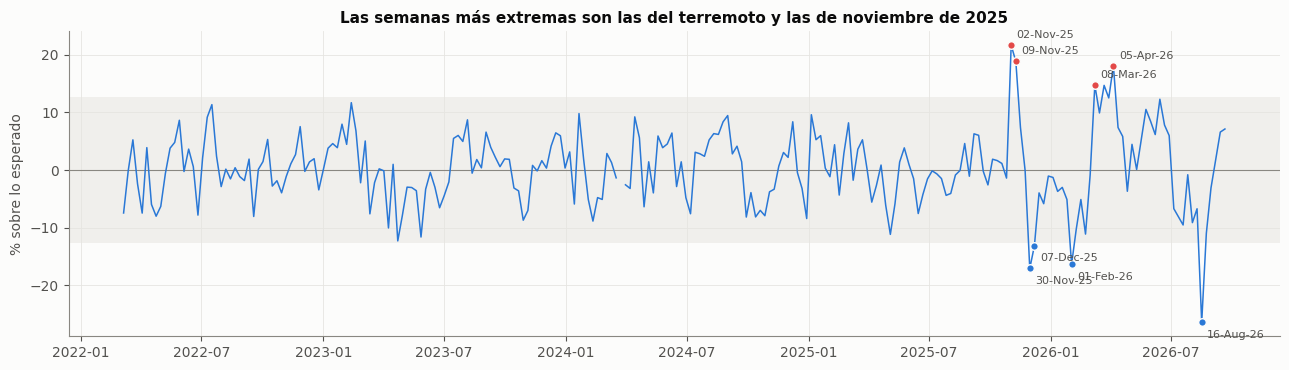

12 más bajas


,residuo %,total,0-14,lluvia z,temp. z
2026-08-16,-26.4,865,73,-0.1,1.9
2025-11-30,-17.1,962,85,-0.3,-0.3
2026-02-01,-16.4,949,85,2.1,-0.7
2025-12-07,-13.2,963,90,-0.3,-0.9
2023-04-23,-12.3,1265,115,-0.8,-0.7
2023-05-28,-11.6,1274,88,0.4,-0.3
2025-05-04,-11.2,1351,133,-0.1,-1.3
2026-02-22,-11.1,1011,118,0.1,-1.0
2026-08-23,-11.0,1048,83,2.9,1.8
2026-02-08,-10.3,1000,84,0.2,-0.8


12 más altas


,residuo %,total,0-14,lluvia z,temp. z
2025-11-02,21.7,1456,98,-0.7,0.4
2025-11-09,18.9,1411,111,-0.6,1.0
2026-04-05,18.1,1228,112,-0.1,0.3
2026-03-08,14.8,1341,126,0.5,0.1
2026-03-22,14.7,1378,135,-0.9,0.1
2026-03-29,12.5,1335,122,0.1,-0.2
2026-06-14,12.3,1442,159,-1.0,0.9
2023-02-12,11.7,1416,120,-0.9,-0.3
2022-07-17,11.4,1541,144,0.3,-0.9
2026-05-24,10.5,1401,153,-1.1,1.5


In [16]:
r = SW["r1_total"].dropna().sort_values()          # la semana incompleta queda fuera
tab = lambda idx: pd.DataFrame({"residuo %": pct(r[idx]).round(1), "total": SW.loc[idx, "total"].astype(int),
                                "0-14": SW.loc[idx, "ped"].astype(int), "lluvia z": SW.loc[idx, "zp"].round(1),
                                "temp. z": SW.loc[idx, "zt"].round(1)}).rename(index=lambda i: f"{i:%Y-%m-%d}")
fig, ax = plt.subplots(figsize=(13, 3.8))
serie = pct(SW["r1_total"])
ax.axhspan(-2 * serie.std(), 2 * serie.std(), color="#f0efec", lw=0); ax.axhline(0, color=MUDO, lw=.8)
ax.plot(serie.index, serie, color=AZUL, lw=1.1)
for i in list(r.index[:4]) + list(r.index[-4:]):
    ax.scatter(i, pct(r[i]), color=ROJO if r[i] > 0 else AZUL, s=30, zorder=3, edgecolor=SUP)
    ax.annotate(f"{i:%d-%b-%y}", (i, pct(r[i])), textcoords="offset points", xytext=(4, 5 if r[i] > 0 else -11), fontsize=8, color=TINTA2)
ax.set_ylabel("% sobre lo esperado"); ax.set_title("Las semanas más extremas son las del terremoto y las de noviembre de 2025")
plt.tight_layout(); plt.show()
print("12 más bajas"); display(tab(r.index[:12]))
print("12 más altas"); tab(r.index[-12:][::-1])

La figura muestra el residuo semanal con las cuatro semanas más bajas y las cuatro más altas marcadas; las tablas dan las doce de cada lado con su anomalía de lluvia y temperatura.

**Las semanas extremas no coinciden con el clima; coinciden con la institución y con el terremoto.**

- **Las más bajas:** la semana que termina el 2026-08-16 (−26,4 %), que contiene el terremoto, y la siguiente (−11,0 %); el 2025-11-30 y el 2025-12-07 (−17,1 % y −13,2 %); y el 2026-02-01 (−16,4 %).
- **Las más altas:** el 2025-11-02 y el 2025-11-09 (+21,7 % y +18,9 %), y un bloque de marzo y abril de 2026 (2026-03-08, +14,8; 03-22, +14,7; 03-29, +12,5; 04-05, +18,1).
- En las doce más altas la anomalía de lluvia va de −1,1 a +0,5 desviaciones: ninguna es una semana de lluvia anómala.
- El salto de noviembre de 2025, de +20 % a −17 % en un mes, es lo que el escalón 2025-11 del control intentaba absorber, y corresponde al desplome de Nueva EPS (ver las conclusiones).
- La semana del 2026-02-01 combina −16,4 % de triage con +2,1 desviaciones de lluvia. Encaja con el efecto de −1,4 % de la lluvia de la sección 4, pero es una sola semana y no basta para sostenerlo.

---
# 9. El día del terremoto del 10 de agosto de 2026 el triage fue la mitad del lunes anterior

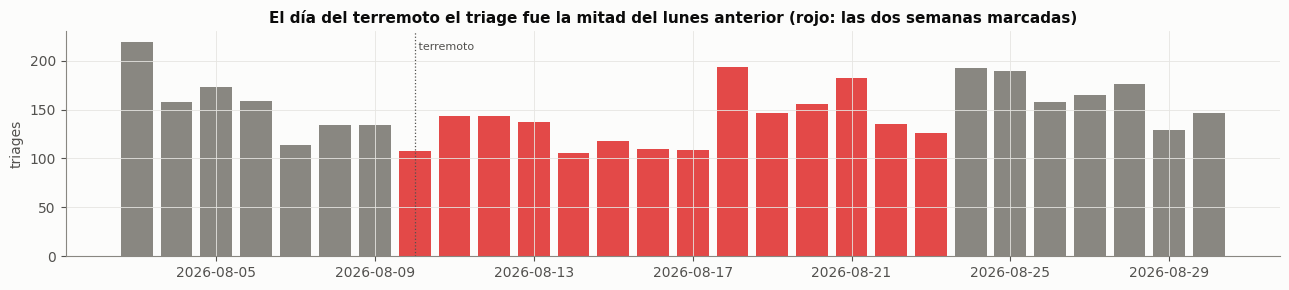

,2026-08-03,2026-08-04,2026-08-05,2026-08-06,2026-08-07,2026-08-08,2026-08-09,2026-08-10,2026-08-11,2026-08-12,2026-08-13,2026-08-14,2026-08-15,2026-08-16,2026-08-17,2026-08-18,2026-08-19,2026-08-20,2026-08-21,2026-08-22,2026-08-23,2026-08-24,2026-08-25,2026-08-26,2026-08-27,2026-08-28,2026-08-29,2026-08-30
total,219.0,158.0,173.0,159.0,114.0,134.0,134.0,108.0,143.0,143.0,137.0,106.0,118.0,110.0,109.0,194.0,146.0,156.0,182.0,135.0,126.0,192.0,189.0,158.0,165.0,176.0,129.0,146.0
ped,17.0,10.0,10.0,12.0,13.0,14.0,14.0,7.0,11.0,13.0,13.0,7.0,10.0,12.0,16.0,12.0,10.0,4.0,13.0,13.0,15.0,8.0,9.0,9.0,11.0,16.0,9.0,11.0
día,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Mon,Tue,Wed,Thu,Fri,Sat,Sun


In [17]:
t_ = D.loc["2026-08-03":"2026-08-30", ["total", "ped"]].copy()
fig, ax = plt.subplots(figsize=(13, 3))
ax.bar(t_.index, t_.total, color=[ROJO if x >= pd.Timestamp("2026-08-10") and x <= pd.Timestamp("2026-08-23") else MUDO for x in t_.index], width=.8)
ax.axvline(pd.Timestamp("2026-08-10"), color=TINTA2, ls=":", lw=.9); ax.text(pd.Timestamp("2026-08-10"), t_.total.max(), " terremoto", fontsize=8, color=TINTA2, va="top")
ax.set_ylabel("triages"); ax.set_title("El día del terremoto el triage fue la mitad del lunes anterior (rojo: las dos semanas marcadas)")
plt.tight_layout(); plt.show()
t_["día"] = t_.index.day_name().str[:3]
t_.T

El lunes del sismo hubo 108 triages, contra 219 el lunes anterior. Los ocho días del 10 al 17 quedan entre 106 y 143 triages por día, y el martes 18 sube a 194. **Una catástrofe grande baja el triage registrado:** la gente no sale, o el registro se interrumpe, y con estos datos no se pueden separar las dos explicaciones. El efecto de dos semanas, −21,5 % [−26,9; −15,7] en el total y −29,5 % [−40,1; −17,2] en los 0-14 años, es el mayor de la tabla de la sección 4, y corresponde a un solo episodio.

---
# 10. Conclusiones y límites

**Qué dicen los datos sobre la pregunta de partida.**

1. **El motivo no hace falta para pronosticar el volumen, y nunca pudo ser entrada** de un pronóstico. Para probar el mecanismo respiratorio, la edad lo sustituye con más historia (6,7 años) y sin interpretación de nadie: el frío y la humedad preceden en una y dos semanas a más consultas de 0-14 años (sección 4).
2. **Con estos datos, las variables externas no mejoran el pronóstico semanal del total.** Los calendarios disponibles al empezar eran calendario disfrazado o demasiado escasos para tener potencia, y ni el clima observado de la semana siguiente (M3) mejora al control (secciones 1, 6 y 7).
3. **El motivo solo añadiría lo que la edad no ve:** la vía respiratoria adulta, la de la incapacidad. Es explicación, no pronóstico.
4. **El control que deja este cuaderno es difícil de superar:** el ingenuo semanal da 5,02 % de MAPE y la persistencia semanal es +0,52. El modelo posterior (C0r, cuaderno 23) usa 28 entradas y ninguna externa: calendario, día de la semana, Fourier, nivel, memoria e indicadores de COVID. Sus cifras no son comparables con las de aquí, porque el horizonte y la ventana difieren.

**Por qué el diseño de este cuaderno no podía ver más.** Medía el nivel semanal, con variables promediadas en la semana, calendarios manuales con ventanas fijas, sobre el total y tras quitar la estacionalidad, que borra los efectos que se repiten en las mismas fechas. Es un diseño que no ve efectos que duran días, que llegan con rezago, que afectan a un subgrupo o que dependen de un cambio brusco. La lectura correcta de los resultados nulos del total es «este diseño no puede separar el efecto del ruido», no «no afecta». Los mecanismos con su propio reloj, medidos en el cuaderno 07, sí dejan huella:

- **La Feria no es un regreso de vacaciones cualquiera.** En los días 0-4 el SOAT sube +36,9 ± 5,5 %, contra +12,5 ± 8,5 % en otros 52 regresos; en el total, la Feria suma +7,3 ± 8,5 %. Aquí, contada como «días de Feria» en el total semanal, daba +0,2 %.
- **De seco a lluvioso, en 0-4 años:** +13,4 ± 15,0 % a los 7-13 días y +10,0 ± 16,4 % a los 14-20 días (17 episodios). Conserva la forma, con subida en la primera y segunda semana y apagado a la cuarta, pero no se distingue de cero. Aquí, como «ruptura» semanal sobre el total, era nula.
- **El asegurador explica los escalones de nivel.** Nueva EPS pasa de 115,8 a 72,2 triages por día entre 2025 y 2026. El 2025-12-01 cae un −47,2 % y Sura sube un +16,8 %. El escalón del 2025-11-01 que este cuaderno metía en el control era, sobre todo, ese desplome, no solo un cambio administrativo; reclasificar el nivel de un triage no cambia el conteo.

**Límites del análisis.**

- El periodo de prueba (2024-2026) coincide con los escalones de Nueva EPS. El control absorbía como ruido el efecto más grande de la red, y la fecha del escalón se eligió mirando la serie: un pronóstico real no la habría tenido en noviembre de 2025.
- Las 81 pruebas de la sección 4 no tienen corrección por comparaciones múltiples, y todo el cuaderno es exploratorio.
- La regresión ridge usa un λ fijo, sin ajustar, y solo se evaluó el horizonte de una semana.
- El efecto de El Niño y La Niña no se puede separar del año, porque ambos fenómenos ocupan años completos y el modelo lleva un efecto fijo por año.
- La ruptura de seca a lluvia (10 semanas) y el enfriamiento brusco (20) son pocos eventos: el efecto mínimo detectable es de 5,5 % o más, sin corregir por autocorrelación.
- Las cifras del control diario de la sección 2.1 se aproximan, sin coincidir, a la medición previa sobre los 615 días: 11,4 % contra 10,13 % de MAPE.
- Lo que el proyecto persigue ahora son los picos contra el nivel reciente, no el MAPE del nivel semanal: el nivel lo mueve la red, y los picos, los eventos, los cambios bruscos y las catástrofes, cada uno con su reloj.